# Lab 4.2 — Agentic Harnesses (Starter)

## Introduction

In Module 2 you built the machinery of tool calling by hand: Lab 2.1 wired a ReAct loop together with prompt templates and regex parsing, and Lab 2.2 climbed the ladder from manual `<tool_call>` parsing to LangChain to MCP. Lab 4.1 then focused on *deliberate reasoning* — searching over candidate thoughts before committing to one.

An **agentic harness** is where those threads meet production. It is everything wrapped *around* the model that turns a chat API into a working agent: the system prompt, the tool suite, the loop that executes tool calls and feeds results back, the context and state management, the permission system that decides which actions need a human, and the environment (your terminal, your filesystem, your repo) that the agent acts on. Claude Code, OpenAI's Codex CLI, Google's Antigravity CLI, and the open-source opencode are all, at their core, the *same loop you wrote in Lab 2.2* — industrialized.

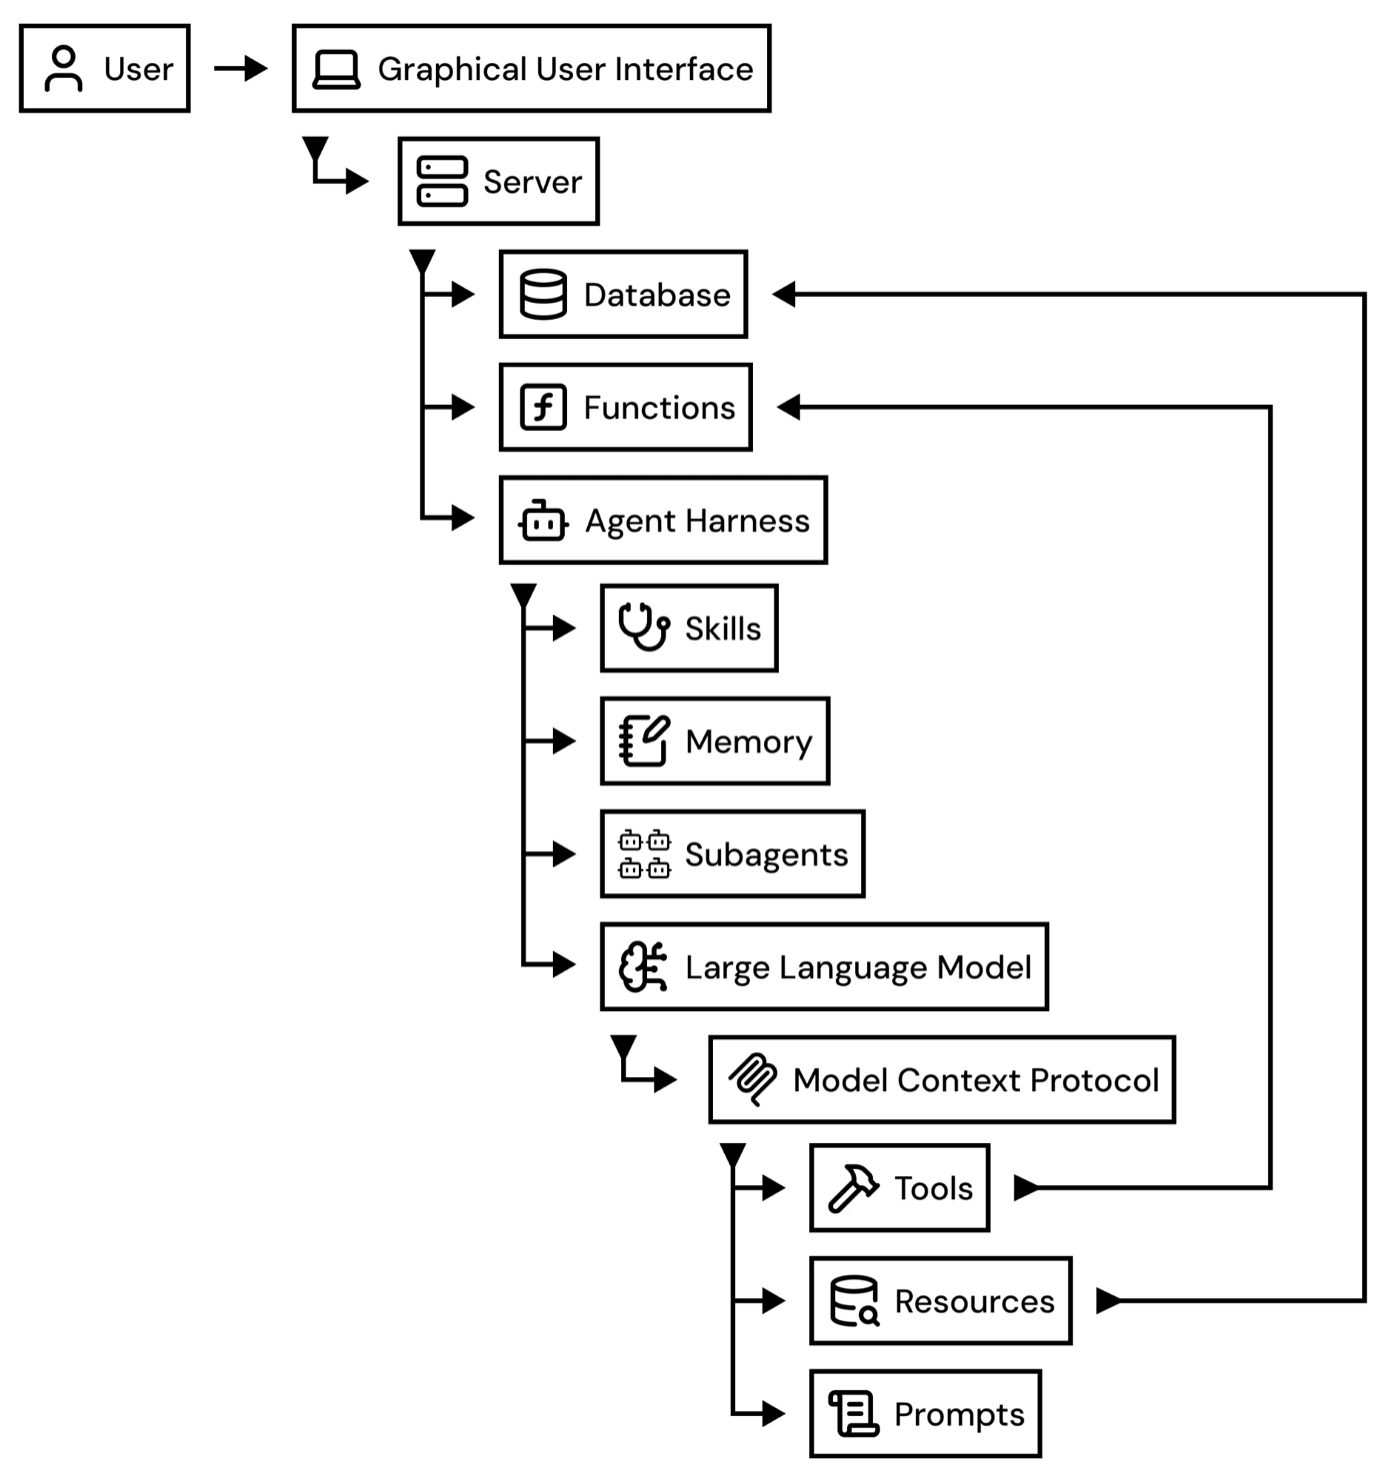

*Where the harness sits in a full application: the server hands work to the **agent harness**, which wraps the LLM together with its skills, memory, and subagents. The model reaches everything else through the **Model Context Protocol** — its tools call back into the application's functions and its resources read from the database, closing the loop.*

This lab has four parts:

- **Part A** — build a minimal harness from scratch (a tool registry plus the agent loop) and trace a full episode through it.
- **Part B** — a guided tour of four production harnesses and the design decisions they share.
- **Part C** — drive one of them, **opencode**, from this notebook and dissect its JSON event stream. opencode is open source and ships free hosted models, so this part works **without any API key or subscription**.
- **Part D** — a harness-agnostic runner: one task submitted to every harness installed on your machine.

> **This is the starter notebook.** Cells marked `# TODO` are for you to implement. Read the docstrings — they specify the exact steps and return types.

## Readings for This Lab

This lab is built **paper-first**, anchored on the study that made harness design a first-class research object.

| Anchor | Paper | What we take from it |
|---|---|---|
| **Primary** | **SWE-agent: Agent-Computer Interfaces Enable Automated Software Engineering** — Princeton (Yang et al., NeurIPS 2024), [arXiv:2405.15793](https://arxiv.org/abs/2405.15793) | The **agent-computer interface (ACI)** thesis: with the model held fixed, *how* tools and their outputs are designed changes task success dramatically. A harness is an ACI. |
| **Support** | **Building Effective Agents** — Anthropic (Schluntz & Zhang, 2024), [anthropic.com/engineering/building-effective-agents](https://www.anthropic.com/engineering/building-effective-agents) | The working definition we use throughout — an agent is a model using tools in a loop — plus the advice to keep the scaffolding as simple as the task allows. |
| **Framing** | **ReAct: Synergizing Reasoning and Acting in Language Models** — Yao et al. (ICLR 2023), [arXiv:2210.03629](https://arxiv.org/abs/2210.03629) | The reason → act → observe cycle you implemented in Lab 2.1. Every harness in this lab is a production-hardened ReAct loop. |

> **A note on timeliness.** Harnesses move fast — the survey in Part B is a snapshot (mid-2026). The *concepts* (the loop, tool registries, permission gates, event streams) are stable; specific flags, model names, and pricing are not. Primary docs: [Claude Code](https://code.claude.com/docs), [Codex CLI](https://developers.openai.com/codex/cli/), [Antigravity CLI](https://github.com/google-antigravity/antigravity-cli), [opencode](https://opencode.ai/docs/).

## Lab Goals

By the end of this lab, you will be able to:

1. **Explain** what an agentic harness is and identify its six recurring components: system prompt, tool suite, agent loop, context management, permission gate, and execution environment.
2. **Implement** a minimal harness — the agent loop over a tool registry — and trace a complete episode through it.
3. **Compare** four production harnesses (Claude Code, Codex CLI, Antigravity CLI, opencode) along vendor, openness, model-coupling, and extensibility axes.
4. **Drive** a real harness (opencode) programmatically from Python, and dissect its JSON event stream to find the same loop at production scale.
5. **Script** a harness-agnostic runner that submits one task to every installed harness through its headless mode.

## Part A — Anatomy of an Agentic Harness

Strip away the branding and every coding agent is the same machine:

```text
                 ┌───────────────────────────────────────────────┐
                 │                  THE HARNESS                  │
                 │                                               │
   user task ───▶│  transcript ─────────▶  model (stateless API) │
                 │      ▲                          │             │
                 │      │                          ▼             │
                 │      │                  tool calls in reply?  │
                 │      │                    │             │     │
                 │  append tool             yes            no    │
                 │  results to               │             │     │
                 │  transcript               ▼             ▼     │
                 │      └───────── execute tools      final      │
                 │               (files, shell, web)  answer ────┼──▶
                 └───────────────────────────────────────────────┘
```

Six components recur in every harness:

| Component | Job | In our mini-harness | In production harnesses |
|---|---|---|---|
| **System prompt** | Teach the model its role, rules, and environment | `SYSTEM_PROMPT` (one sentence) | Thousands of tokens, tuned per release |
| **Tool suite** | The verbs the agent can perform | `TOOLS` registry (3 tools) | `read` / `write` / `edit` / `bash` / `grep` / `glob` + MCP |
| **Agent loop** | Call model → execute tools → feed results back → repeat | `run_agent()` | The same, plus streaming, retries, cancellation |
| **Context management** | Decide what the (stateless) model sees on each call | a growing `transcript` list | Compaction, caching, subagents with fresh contexts |
| **Permission gate** | Which tool calls run unattended vs. need approval | omitted here (see Parts B–C) | Allowlists, approval modes, OS sandboxes |
| **Execution environment** | Where side effects land | a throwaway workspace directory | Your repo, containers, remote VMs |

SWE-agent's central finding is that these choices are not plumbing — they are *the* lever. Holding the model fixed and redesigning only the interface (how file views are windowed, how errors are phrased, how search results are truncated) moved resolution rates on real GitHub issues by large margins. The harness is not neutral packaging around intelligence; it is part of the system's intelligence.

We now build the smallest harness that exhibits the real behavior. To keep it deterministic and free, the "model" is **scripted** — the loop, tools, and workspace are real.

In [ ]:
# ============================================================================
# Setup — stdlib only; no API keys required anywhere in this lab
# ============================================================================

from __future__ import annotations

import json
import os
import re
import shutil
import subprocess
import tempfile
import textwrap
from pathlib import Path

ANSI_RE = re.compile(r"\x1b\[[0-9;]*m")

def strip_ansi(s: str) -> str:
    """Remove ANSI color codes from CLI output."""
    return ANSI_RE.sub("", s)

print("Setup complete.")

In [ ]:
# ============================================================================
# The tool suite — the verbs our mini-harness exposes to the model
# ============================================================================

# Each tool receives the workspace (its sandbox) and a dict of arguments, and
# returns a STRING. Tool results must serialize into the transcript, because
# the model only ever sees text — formatting that text well is exactly the
# "agent-computer interface" design problem SWE-agent studies.

def tool_list_dir(workspace: Path, args: dict) -> str:
    entries = sorted(p.name for p in workspace.iterdir())
    return "\n".join(entries) if entries else "(empty directory)"

def tool_read_file(workspace: Path, args: dict) -> str:
    target = workspace / args["path"]
    if not target.exists():
        return f"ERROR: {args['path']} does not exist"
    return target.read_text()

def tool_write_file(workspace: Path, args: dict) -> str:
    target = workspace / args["path"]
    target.write_text(args["content"])
    return f"Wrote {len(args['content'])} characters to {args['path']}"

TOOLS = {
    "list_dir": tool_list_dir,
    "read_file": tool_read_file,
    "write_file": tool_write_file,
}

# The schema a harness sends to the model with every request, so the model
# knows what it may call — compare Lab 2.2, where you wrote the same thing
# for LangChain's @tool and for MCP:
TOOL_SPECS = [
    {"name": "list_dir", "description": "List files in the workspace.",
     "parameters": {}},
    {"name": "read_file", "description": "Read a file from the workspace.",
     "parameters": {"path": "string"}},
    {"name": "write_file", "description": "Create or overwrite a file.",
     "parameters": {"path": "string", "content": "string"}},
]

SYSTEM_PROMPT = (
    "You are a coding agent operating on a workspace directory. "
    "Use the available tools to complete the user's task. "
    "When the task is done, reply without tool calls to end the episode."
)

print(f"{len(TOOLS)} tools registered: {', '.join(TOOLS)}")

In [ ]:
# ============================================================================
# ScriptedModel — a stand-in for the LLM, so the loop is visible and free
# ============================================================================

# A real harness makes an API call here (the ChatAnthropic pattern from
# Lab 2.2) and the provider returns text plus zero or more structured tool
# calls. We replay a pre-scripted episode instead: identical interface,
# deterministic output, zero cost.

class ScriptedModel:
    """Callable that mimics a chat-completions API with native tool calling.

    Each call consumes the next scripted response, regardless of transcript
    content. The response shape is the one every provider converged on:
        {"text": str, "tool_calls": [{"name": str, "args": dict}, ...]}
    """

    def __init__(self, script: list[dict]):
        self.script = list(script)
        self.calls = 0

    def __call__(self, transcript: list[dict]) -> dict:
        self.calls += 1
        if not self.script:
            return {"text": "(script exhausted)", "tool_calls": []}
        return self.script.pop(0)

print("ScriptedModel defined.")

### TODO: Part A — Implement the agent loop

Implement `run_agent` below. It is the heart of every harness in this lab: a loop that calls the model, executes whatever tools the model requested, appends the results to the transcript, and stops when a reply contains no tool calls. The docstring specifies the exact steps and message shapes; the demo cell after it should then reproduce the episode described in the Part A text.

In [ ]:
# ============================================================================
# run_agent — the agent loop. This ~25-line function IS the harness core.
# ============================================================================

def run_agent(model, task: str, workspace: Path, max_turns: int = 8):
    """
    Run one agentic episode: loop until the model stops calling tools.

    Returns (final_text, transcript). The transcript is the full message
    history — system prompt, user task, every model reply, every tool result.

    Steps:
        1. Initialize `transcript` with two dicts:
           {"role": "system", "content": SYSTEM_PROMPT} and
           {"role": "user", "content": task}
        2. Loop up to max_turns times:
           a. Call model(transcript) — the model is stateless, so the whole
              transcript is passed on every call. It returns
              {"text": str, "tool_calls": list}.
           b. Append an assistant message that carries BOTH fields:
              {"role": "assistant", "content": ..., "tool_calls": ...}
           c. If response["tool_calls"] is empty, return
              (response["text"], transcript) — this is the stop condition.
           d. Otherwise execute each call via TOOLS[call["name"]](workspace,
              call["args"]) and append {"role": "tool", "name": ...,
              "content": result} for each.
        3. If the loop exhausts, return ("(stopped: max_turns reached)",
           transcript).
    """
    # TODO: Implement the agent loop
    pass

print("run_agent defined.")

In [ ]:
# Run this cell after implementing run_agent above.
# ============================================================================
# Demo — one scripted episode through the mini-harness
# ============================================================================

workspace = Path(tempfile.mkdtemp(prefix="mini_harness_"))
(workspace / "README.md").write_text("# Demo project\n")
(workspace / "app.py").write_text("print('hi')\n")

TASK = "Create MANIFEST.txt listing every file in the workspace, then verify it."

episode = ScriptedModel([
    {"text": "I'll inspect the workspace first.",
     "tool_calls": [{"name": "list_dir", "args": {}}]},
    {"text": "Two files. Writing the manifest now.",
     "tool_calls": [{"name": "write_file",
                     "args": {"path": "MANIFEST.txt",
                              "content": "README.md\napp.py\n"}}]},
    {"text": "Verifying what was written.",
     "tool_calls": [{"name": "read_file", "args": {"path": "MANIFEST.txt"}}]},
    {"text": "Done: MANIFEST.txt lists README.md and app.py.",
     "tool_calls": []},
])

final, transcript = run_agent(episode, TASK, workspace)

for msg in transcript:
    role = msg["role"].upper().ljust(9)
    body = textwrap.shorten(str(msg["content"]), width=66)
    print(f"{role} {body}")
    for call in msg.get("tool_calls", []):
        print(f"          -> tool call: {call['name']}({json.dumps(call['args'])[:46]})")

print()
print(f"Final answer : {final}")
print(f"Model calls  : {episode.calls}")
print(f"Transcript   : {len(transcript)} messages (grew from 2 — this growth "
      f"is what real harnesses must manage)")
print(f"Workspace now: {sorted(p.name for p in workspace.iterdir())}")

### What just happened

Four model calls, three tool executions, one real file created — and the entire "intelligence" was a hard-coded script. That is the point: **the loop does not care whether the model is scripted, local, or a frontier API.** Swap `ScriptedModel` for an API client with native tool calling (the Lab 2.2 pattern) and this becomes a real agent.

Three observations to carry into the rest of the lab:

1. **The model is stateless; the harness owns all state.** Every call re-sends the full transcript. Watch for this again in Part C, where opencode's token accounting makes it *measurable*.
2. **The stop condition is the absence of tool calls.** There is no special "done" token — every production harness uses this same convention.
3. **Tool results are just strings appended to the transcript.** How you format them — error messages, truncation, directory listings — is interface design, and SWE-agent's core finding is that those formatting choices move success rates substantially.

Everything we omitted — permissions, streaming, context compaction, retries, sandboxing, observability — is precisely where production harnesses spend their engineering budget. On to those.

## Part B — Four Production Harnesses

The 2025–2026 wave of terminal coding agents converged on the Part A architecture with remarkable speed. We survey four:

| | **Claude Code** | **Codex CLI** | **Antigravity CLI** | **opencode** |
|---|---|---|---|---|
| Vendor | Anthropic | OpenAI | Google | SST / community |
| First shipped | Feb 2025 | Apr 2025 | May 2026 (successor to Gemini CLI, 2025) | 2025 |
| Open source | No (proprietary) | Yes — Apache-2.0 | CLI: unclear; predecessor Gemini CLI was Apache-2.0 | Yes — MIT |
| Implementation | TypeScript (Node) | Rust | Go | TypeScript core + Go TUI |
| Models | Claude family | GPT-5 / Codex family (+ local via `--oss`) | Gemini 3 family | 75+ providers, incl. free hosted + local (Ollama) |
| Account needed to start | Claude subscription or API key | ChatGPT subscription or API key | Google account | **None** (free tier) — or bring any key |
| Interactive command | `claude` | `codex` | `agy` | `opencode` |
| Headless command | `claude -p "…"` | `codex exec "…"` | `agy -p "…"` | `opencode run "…"` |
| Extensibility | MCP, skills, hooks, subagents, plugins, SDK | MCP, AGENTS.md, profiles | MCP, skills, hooks, subagents, plugins | MCP, custom agents, plugins, HTTP server |

The subsections below give each harness a closer look: how you would install and use it, and what it does differently.

### Claude Code (Anthropic)

The harness that defined the category: a terminal agent that lives in your repo, reads and edits files, runs shell commands, and asks permission before side effects.

```bash
npm install -g @anthropic-ai/claude-code     # or native installers / brew
claude                                        # interactive TUI; sign in with a
                                              # Claude subscription or API key
claude -p "fix the failing test" --allowedTools "Bash,Edit"   # headless mode
```

Design notes:

- **Permission-first UX.** File writes and shell commands prompt for approval by default; autonomy is expanded per-tool (`--allowedTools`), per-project (settings files), or wholesale in sandboxed environments.
- **Project memory.** A `CLAUDE.md` (or `AGENTS.md`) at the repo root is injected into the system prompt — persistent, versioned instructions for the agent.
- **Deep extensibility.** MCP client for external tools, skills (reusable instruction packages), hooks (shell commands that intercept the loop), and subagents with fresh contexts.
- **Harness as a library.** The same loop is exposed programmatically as the Claude Agent SDK — evidence that the harness, not the chat UI, is the product.

### OpenAI Codex CLI

OpenAI's terminal agent, open-sourced (Apache-2.0, [github.com/openai/codex](https://github.com/openai/codex)) in April 2025 and later rewritten from TypeScript to Rust — the whole harness is readable source.

```bash
npm install -g @openai/codex     # or: brew install codex
codex                            # sign in with a ChatGPT account (or API key)
codex exec "write unit tests for utils.py"    # headless mode
```

Design notes:

- **Sandbox-first, not approval-first.** Commands run inside OS-level sandboxes by default (Seatbelt on macOS, Landlock on Linux) with network disabled; the agent must *ask to escalate* rather than ask to act.
- **Approval modes** (`suggest` → `auto-edit` → `full-auto`) make the autonomy dial explicit and coarse, instead of per-tool allowlists.
- **`AGENTS.md`** project memory — the convention that the rest of the ecosystem is adopting.
- **Local models.** The `--oss` flag points the same harness at open-weight models served by Ollama — a clean demonstration that harness and model are separable.

### Antigravity CLI (Google)

Google's entry has the most tangled lineage: Gemini CLI (2025, Apache-2.0, TypeScript) was folded into the **Antigravity** agentic-development platform at I/O 2026, re-emerging as `agy` — a Go rewrite that shares its agent harness with the Antigravity desktop IDE. One harness, multiple surfaces.

```bash
curl -fsSL https://antigravity.google/cli/install.sh | bash
agy                              # sign in with a Google account
```

Design notes:

- **Shared harness.** The CLI and the desktop app run the same core, so agent behavior is identical across surfaces — an explicit design goal, and a useful mental model for "harness" as distinct from "interface."
- **Orchestration emphasis.** First-class support for multiple parallel agents, custom subagent workflows, and *scheduled* background tasks.
- **Feature parity with the field:** skills, hooks, subagents, and plugins (formerly Gemini CLI extensions), plus MCP.
- **Caveat:** the newest of the four — commands and flags shown here are the launch-era spelling (mid-2026); check `agy --help` against the current docs.

### opencode (open source)

A community harness (from the SST team, MIT-licensed, [opencode.ai](https://opencode.ai)) built to be **provider-agnostic**: a client/server core in TypeScript with a Go terminal UI, able to drive 75+ model providers — including a rotating set of free hosted models under the `opencode/` namespace and fully local models via Ollama.

```bash
brew install sst/tap/opencode    # or: npm i -g opencode-ai
opencode                         # TUI — works immediately on free models
opencode run --model opencode/deepseek-v4-flash-free "explain this repo"
opencode serve --port 4096       # the same harness as an HTTP API
```

Design notes:

- **Model-agnosticism as the product.** Auth is optional; any provider key works; models can be switched mid-session. The harness is the constant, the model is a plug-in.
- **Harness as a service.** `opencode serve` exposes sessions, messages, and tool events over HTTP — other programs (or other agents) can drive it.
- **Same convergent feature set:** plan/build agents with per-tool permissions, `AGENTS.md`, MCP, plugins.
- **Why this lab uses it:** no account, no cost, readable source, and — most importantly for us — a `--format json` flag that emits the harness's raw event stream.

### Convergent design: what they all share

Four vendors, four codebases, one architecture. All four harnesses:

1. **Run the Part A loop** — stateless model calls over a growing transcript; stop when a reply contains no tool calls.
2. **Ship a small, orthogonal tool suite** — read / write / edit / bash / grep / glob, plus a "spawn subagent" tool. Compare `TOOL_SPECS`: the same shape, with more entries.
3. **Read a project memory file** — persistent instructions injected into the system prompt, converging on the cross-vendor `AGENTS.md` convention.
4. **Speak MCP** — the protocol from Lab 1.2 and Lab 2.2 is the universal extension port for third-party tools.
5. **Offer a headless mode** — one-shot, scriptable, CI-friendly. Part D exploits exactly this.
6. **Gate side effects** — approval prompts, allowlists, or OS sandboxes; write access is never free by default.
7. **Manage context automatically** — compaction/summarization when the transcript outgrows the model's window.

Where they *differ* is strategy, not architecture: **model coupling** (Claude Code and Antigravity funnel you to their vendor's models; Codex partially; opencode is deliberately model-agnostic), **openness** (Apache/MIT source vs. proprietary), and **the safety dial** (Codex leads with OS sandboxes; Claude Code with per-action approval; the others blend both). When you evaluate the next harness to appear — and there will be a next one — this seven-item checklist is the fast way to see past its marketing.

## Part C — Driving a Real Harness: opencode

Time to run the real thing. We use opencode because it is the only one of the four that works with **zero credentials**: it ships free hosted models (the `opencode/…-free` family), so every cell below runs on a clean machine. The other three would behave identically — given a subscription and their flag spellings from Part B.

Two features make opencode ideal for dissection:

- `opencode run "…"` — one-shot headless mode (its `claude -p`).
- `--format json` — instead of pretty text, the harness emits its **raw event stream**: one JSON object per line. This is the Part A loop, serialized.

The event types we care about:

| Event type | Meaning | Part A equivalent |
|---|---|---|
| `step_start` | one model call begins | top of the `for turn …` loop |
| `tool_use` | a tool ran — name, input, output, status | `TOOLS[name](workspace, args)` |
| `step_finish` | model call ended; `reason` is `"tool-calls"` or `"stop"`; carries token counts | the `if not response["tool_calls"]` check |
| `text` | assistant text (the final answer) | `final` |

In [ ]:
# ============================================================================
# Sanity check — opencode install + today's free-model list
# ============================================================================

assert shutil.which("opencode"), (
    "opencode not found — install it first:\n"
    "  brew install sst/tap/opencode    # or: npm install -g opencode-ai\n"
    "  # or: curl -fsSL https://opencode.ai/install | bash"
)

version = subprocess.run(["opencode", "--version"],
                         capture_output=True, text=True).stdout.strip()

models_out = subprocess.run(["opencode", "models"],
                            capture_output=True, text=True).stdout
free_models = [m.strip() for m in models_out.splitlines()
               if m.strip().endswith("-free")]

# The free tier rotates over time — pick whatever is free today.
FREE_MODEL = free_models[0] if free_models else "opencode/deepseek-v4-flash-free"

print(f"opencode version : {version}")
print(f"free models today: {free_models}")
print(f"using            : {FREE_MODEL}")

In [ ]:
# ============================================================================
# run_opencode — drive the harness from Python via its headless mode
# ============================================================================

def run_opencode(prompt: str, workspace: Path, as_json: bool = False,
                 timeout: int = 240) -> str:
    """One-shot opencode run inside `workspace` (its cwd is its sandbox).

    Gotcha discovered while building this lab: opencode resolves its project
    directory from the $PWD environment variable, which subprocess's `cwd=`
    does NOT update — so we must set both, or the agent operates on the
    notebook's directory instead of the sandbox. Harness behavior is full of
    environment details like this; when in doubt, ask the agent to print its
    working directory.
    """
    cmd = ["opencode", "run", "--model", FREE_MODEL]
    if as_json:
        cmd += ["--format", "json"]
    cmd.append(prompt)
    env = {**os.environ, "PWD": str(workspace)}
    proc = subprocess.run(cmd, cwd=workspace, env=env, capture_output=True,
                          text=True, timeout=timeout)
    if proc.returncode != 0:
        raise RuntimeError(f"opencode failed:\n{proc.stderr[-2000:]}")
    return strip_ansi(proc.stdout)

# Smoke test: a pure-text task (no tools needed)
oc_workspace = Path(tempfile.mkdtemp(prefix="opencode_lab_"))
print(run_opencode("In exactly one sentence: what does a coding agent's "
                   "'bash' tool let it do?", oc_workspace))

In [ ]:
# ============================================================================
# A real agentic episode — the task we scripted in Part A, now for real
# ============================================================================

(oc_workspace / "README.md").write_text("# Demo project\n")
(oc_workspace / "app.py").write_text("print('hi')\n")

out = run_opencode(
    "Create MANIFEST.txt listing every file in this directory (one filename "
    "per line), then read it back to verify. Keep your final reply to one "
    "sentence.",
    oc_workspace,
)
print(out)
print("-" * 60)
print("Workspace now:", sorted(p.name for p in oc_workspace.iterdir()))
manifest = oc_workspace / "MANIFEST.txt"
print("MANIFEST.txt :",
      manifest.read_text().strip().replace("\n", ", ") if manifest.exists()
      else "(not created)")

### Dissecting the event stream

Rerun a task with `--format json` and the harness narrates its own loop: every model step, every tool call with its exact input and output, every stop decision, and per-step token and cost accounting. `summarize_events` below reduces that firehose to a readable trace — one line per event, grouped by model step.

### TODO: Part C — Implement the event-stream summarizer

Implement `summarize_events` below. It receives the raw `--format json` output (one JSON object per line) and must reduce it to a trace of the loop: which model step we are in, which tools ran with which inputs, and why each step ended. The docstring specifies the exact record shapes; the printing code underneath will work once your function returns the list.

In [ ]:
# ============================================================================
# summarize_events — reduce the JSON event stream to a readable loop trace
# ============================================================================

def summarize_events(jsonl: str) -> list[dict]:
    """
    Parse `opencode run --format json` output into a compact trace.

    Returns a list of {"step", "kind", "detail"} dicts, where `step` counts
    model calls (step_start events) and `kind` is one of
    "model_call", "tool", "text", "finish".

    Steps:
        1. Iterate over jsonl.splitlines(); skip lines that don't start
           with "{"; json.loads the rest. Each event has event["type"] and
           event["part"] (a dict).
        2. On type "step_start": increment the step counter and append
           {"step", "kind": "model_call", "detail": "model call begins"}.
        3. On type "tool_use": read part["tool"] and part["state"] (which
           holds "input", "output", "status"); append a "tool" record whose
           detail shows the tool name, (truncated) JSON input, and status.
        4. On type "text": append a "text" record with (truncated)
           part["text"].
        5. On type "step_finish": append a "finish" record whose detail shows
           part["reason"] ("tool-calls" vs "stop") and part["tokens"]
           (input / output / cache.read).
        6. Return the trace list.
    """
    # TODO: Implement the summarizer
    pass

raw = run_opencode(
    "Read MANIFEST.txt, then append a final line 'checked' to it using your "
    "tools. Reply DONE when finished.",
    oc_workspace, as_json=True,
)

print(raw.splitlines()[0][:160], "...")   # peek at the raw material

for row in (summarize_events(raw) or []):   # prints nothing until implemented
    print(f"step {row['step']}  {row['kind']:<10} {row['detail']}")

### Same loop, real harness

Line the trace up against Part A:

- Each `model_call → tool → finish(reason=tool-calls)` block is one iteration of `run_agent`'s loop, and the episode ends with `finish(reason=stop)` — the "no tool calls" stop condition, verbatim.
- The tool names differ (`read`, `edit`, `bash`, …) but they are entries in a `TOOLS`-style registry, and each `tool_use` event's `input`/`output` pair is exactly what gets appended to the transcript.
- Watch the token counts across steps: `cache_read` grows as the full transcript is re-sent on every call — the statelessness from Part A, now *measured*. (And cost stays 0 — free tier.)

The trace also shows something our mini-harness lacked: per-call `status` and timing on every tool execution. Production harnesses are **observability platforms** as much as loops — a thread Module 6 picks up when we monitor agent trajectories for failures and sabotage.

## Part D — One Task, Four Harnesses

The clearest evidence of convergence: at the command line, the four harnesses are practically interchangeable. Same shape — `<binary> <headless-flag> "<task>"` — different vendors:

```bash
claude -p     "In one sentence, define an 'agentic harness'."
codex exec    "In one sentence, define an 'agentic harness'."
agy -p        "In one sentence, define an 'agentic harness'."
opencode run  "In one sentence, define an 'agentic harness'."
```

The driver below detects which harnesses are installed, submits the same task to each, and skips the rest. On a machine with no accounts at all, only opencode answers — which is precisely why it anchors this lab. Claude Code, Codex, and Antigravity will each answer *if* you are signed in to them (Part B's auth requirements apply), and note that this cell spends real subscription or API quota on any harness it reaches.

In [ ]:
# ============================================================================
# The harness registry — one headless invocation per harness
# ============================================================================

PROBE_TASK = "In one sentence, define an 'agentic harness' for a coding agent."

HARNESSES = {
    "Claude Code":     ["claude", "-p", PROBE_TASK],
    "Codex CLI":       ["codex", "exec", PROBE_TASK],
    "Antigravity CLI": ["agy", "-p", PROBE_TASK],
    "opencode":        ["opencode", "run", "--model", FREE_MODEL, PROBE_TASK],
}

for name, cmd in HARNESSES.items():
    status = "installed" if shutil.which(cmd[0]) else "not installed — will skip"
    print(f"{name:<16} `{cmd[0]}`".ljust(30) + status)

In [ ]:
# ============================================================================
# Ask every installed harness the same question
# ============================================================================

for name, cmd in HARNESSES.items():
    print(f"=== {name} " + "=" * max(0, 56 - len(name)))
    if not shutil.which(cmd[0]):
        print("skipped (not installed)\n")
        continue
    scratch = Path(tempfile.mkdtemp(prefix="probe_"))   # empty cwd per run
    try:
        proc = subprocess.run(cmd, cwd=scratch,
                              env={**os.environ, "PWD": str(scratch)},
                              capture_output=True, text=True, timeout=180)
        reply = strip_ansi(proc.stdout).strip() or strip_ansi(proc.stderr).strip()
        print(textwrap.fill(reply[-700:], width=76) if reply else "(no output)")
    except subprocess.TimeoutExpired:
        print("skipped (timed out — is this harness authenticated?)")
    except OSError as exc:
        print(f"skipped ({exc})")
    print()

## Reflection and Key Takeaways

### Key Takeaways

1. **A harness is the loop, not the model.** Part A's ~25-line `run_agent` — stateless model calls over a growing transcript, tools executed in between, stop on a no-tool reply — is the same architecture inside all four production tools.
2. **The interface is the leverage.** SWE-agent's result generalizes: with the model held fixed, tool design and result formatting change outcomes. Harness engineering *is* capability engineering.
3. **The model is stateless; the harness owns state.** You saw this twice — as transcript growth in Part A, and as per-step token/cache accounting in Part C.
4. **The ecosystem is converging.** Small orthogonal tool suites, `AGENTS.md` project memory, MCP as the extension port, headless modes, gated side effects: four vendors, one architecture. Differentiation lives in models, openness, and the safety dial.
5. **Open implementations make harnesses studyable.** Codex CLI and opencode are readable source, and opencode's free tier removes cost as a barrier — the whole Part C dissection ran without an account.

### Design Principles

- Keep the tool suite small and orthogonal, and format tool output *for the model*, not for humans.
- Make every side effect observable — events, statuses, token accounting. You cannot govern what you cannot see.
- Gate writes and shell access by default; expand autonomy deliberately, not accidentally.
- Build headless-first: a scriptable harness composes into CI, cron jobs, and other agents.

### Limitations and Open Questions

- Our mini-harness scripted the model, so nothing in Part A measured *reasoning* quality — only loop mechanics. Lab 4.1 covered the reasoning side.
- Free-tier hosted models are small and rate-limited; do not draw capability conclusions from them.
- Part B is a mid-2026 snapshot of a fast-moving market — verify commands, models, and licenses against the linked docs before relying on them.
- We never exercised permission UX: every run happened in a throwaway directory where nothing could go wrong. How approval fatigue, sandboxes, and autonomy dials interact with real safety is an open design problem — and the monitoring half of that story is Module 6.

## Reflection Questions

1. **Interface design.** Find one formatting decision in the Part C event stream — for example, how the `read` tool renders a directory listing inside `<entries>` tags, or how errors are phrased. Why might the harness authors have chosen that representation over raw `ls`-style output, and how would you A/B test the choice?
2. **Convergence.** All four harnesses expose nearly the same tool suite. If the tools are commoditized, where does a harness actually compete — and which of those dimensions would you expect to still matter in five years?
3. **Statelessness and cost.** Using Part C's per-step token counts, describe how input tokens scale with episode length. What does automatic compaction trade away to control that growth, and when would that trade bite an agent working on your codebase?
4. **Permission philosophy.** Codex CLI leads with OS-enforced sandboxes and escalation requests; Claude Code leads with per-action approval and allowlists. Describe one failure mode each approach prevents that the other does not.
5. **Harness as a platform.** `opencode serve` exposes the loop over HTTP, and Claude Code exposes it as an SDK. What new failure modes appear when a harness stops being an interactive tool and becomes a service that *other programs* — or other agents — can drive?